# Notebook 14 – EDA Mini Challenge

Independent EDA on a **different, unseen dataset**: the Titanic passenger dataset (891 passengers, 15 columns). Question: *what factors are associated with survival?*

**Sprint 4 – Data Inspection & Exploratory Data Analysis**  
Workflow: `Load → Inspect → Understand → Analyze → Visualize → Identify Problems → Document Findings`  
**Dataset:** Telco Customer Churn (IBM sample data, 7,043 customers × 21 columns)

**Note:** the challenge brief gives no instructions, so this notebook carries the full workflow by itself: load → understand → inspect → data types → missing → duplicates → numerical → categorical → outliers → distributions → correlations → visualizations → patterns → business insights → recommendations.

### Topic Explanation

This topic focuses on load the dataset. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 1. Load the dataset

In [1]:
import os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
PATH = "../data/titanic.csv"
if not os.path.exists(PATH):
    PATH = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
df = pd.read_csv(PATH)
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### Topic Explanation

This topic focuses on understand the dataset. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 2. Understand the dataset

**Source:** seaborn-data repository (a version of the classic Titanic passenger list). **Domain:** transport/maritime history, used as a classic classification problem. **Grain:** one row per passenger. **Target:** `survived` (0/1). **Columns:** `survived`, `pclass` (ticket class 1–3), `sex`, `age`, `sibsp` (siblings/spouses aboard), `parch` (parents/children aboard), `fare`, `embarked`/`embark_town` (port), `class`, `who`, `adult_male`, `deck`, `alive`, `alone`. **Warning:** `class`, `who`, `adult_male`, `alive`, `embark_town`, `alone` are *derived/duplicate* columns; `alive` is a literal copy of the target (**data leakage**).

### Topic Explanation

This topic checks each column's stored data type and non-null count so data can be interpreted correctly.

## 3. Inspect structure and 4. Identify data types

In [2]:
print("Shape:", df.shape); df.info()
display(df.describe().T)
display(df.describe(include=["object", "category", "bool"]).T)
num_cols = ["age", "fare", "sibsp", "parch"]
cat_cols = ["pclass", "sex", "embarked", "class", "who", "adult_male", "deck", "embark_town", "alone"]
print("\nLeakage check – 'alive' vs 'survived':"); print(pd.crosstab(df.survived, df.alive))

Shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


,count,mean,std,min,25%,50%,75%,max
survived,891.0,0.383838,0.486592,0.00,0.0000,0.0000,1.0,1.0000
pclass,891.0,2.308642,0.836071,1.00,2.0000,3.0000,3.0,3.0000
age,714.0,29.699118,14.526497,0.42,20.1250,28.0000,38.0,80.0000
sibsp,891.0,0.523008,1.102743,0.00,0.0000,0.0000,1.0,8.0000
parch,891.0,0.381594,0.806057,0.00,0.0000,0.0000,0.0,6.0000
fare,891.0,32.204208,49.693429,0.00,7.9104,14.4542,31.0,512.3292


,count,unique,top,freq
sex,891,2,male,577
embarked,889,3,S,644
class,891,3,Third,491
who,891,3,man,537
adult_male,891,2,True,537
deck,203,7,C,59
embark_town,889,3,Southampton,644
alive,891,2,no,549
alone,891,2,True,537



Leakage check – 'alive' vs 'survived':
alive      no  yes
survived          
0         549    0
1           0  342


**Findings:** 891 rows × 15 columns. Numerical: `age`, `fare`, `sibsp`, `parch`; ordinal: `pclass`; categorical: `sex`, `embarked`, `who`, `deck`, …; booleans: `adult_male`, `alone`. No identifier column. `alive` duplicates the target exactly (must be excluded). `class`/`pclass`, `embarked`/`embark_town` carry identical information.

### Topic Explanation

This topic finds absent values and quantifies how much data is missing in each field.

## 5. Missing values  and  6. Duplicates

,missing,pct
age,177,19.9
embarked,2,0.2
deck,688,77.2
embark_town,2,0.2


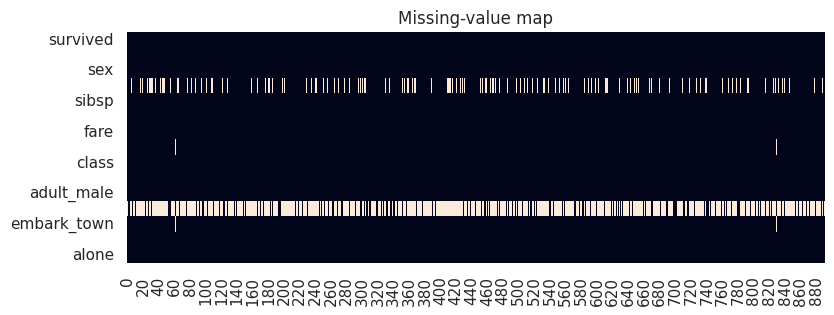

Duplicated rows: 107
Age missing by class:
{1: 0.139, 2: 0.06, 3: 0.277}
Age missing vs survival:
{False: 0.406, True: 0.294}


In [3]:
miss = pd.DataFrame({"missing": df.isnull().sum(), "pct": (df.isnull().mean() * 100).round(1)}); miss = miss[miss.missing > 0]; display(miss)
plt.figure(figsize=(9, 3)); sns.heatmap(df.isnull().T, cbar=False); plt.title("Missing-value map"); plt.show()
print("Duplicated rows:", df.duplicated().sum())
print("Age missing by class:"); print(df.groupby("pclass").age.apply(lambda s: s.isnull().mean()).round(3).to_dict())
print("Age missing vs survival:"); print(df.groupby(df.age.isnull()).survived.mean().round(3).to_dict())

**Findings:** `age` is missing for 177 passengers (19.9%), `deck` for 688 (77.2%!), `embarked`/`embark_town` for 2 each. Missing age is more common in 3rd class (not random → MAR). `deck` is missing for most non-first-class passengers (cabin never recorded) – a *structural* gap. There are 107 fully duplicated rows; with no ID column they cannot be distinguished from different passengers with identical attributes, so they need a judgement call (likely valid siblings/families with the same ticket attributes).

### Topic Explanation

This topic distinguishes input features used for analysis from the target variable the analysis may aim to explain or predict.

## 7. Analyse numerical features  and  10. Distributions

,mean,median,std,min,max,skew,kurt
age,29.70,28.00,14.53,0.42,80.00,0.39,0.18
fare,32.20,14.45,49.69,0.00,512.33,4.79,33.40
sibsp,0.52,0.00,1.10,0.00,8.00,3.70,17.88
parch,0.38,0.00,0.81,0.00,6.00,2.75,9.78


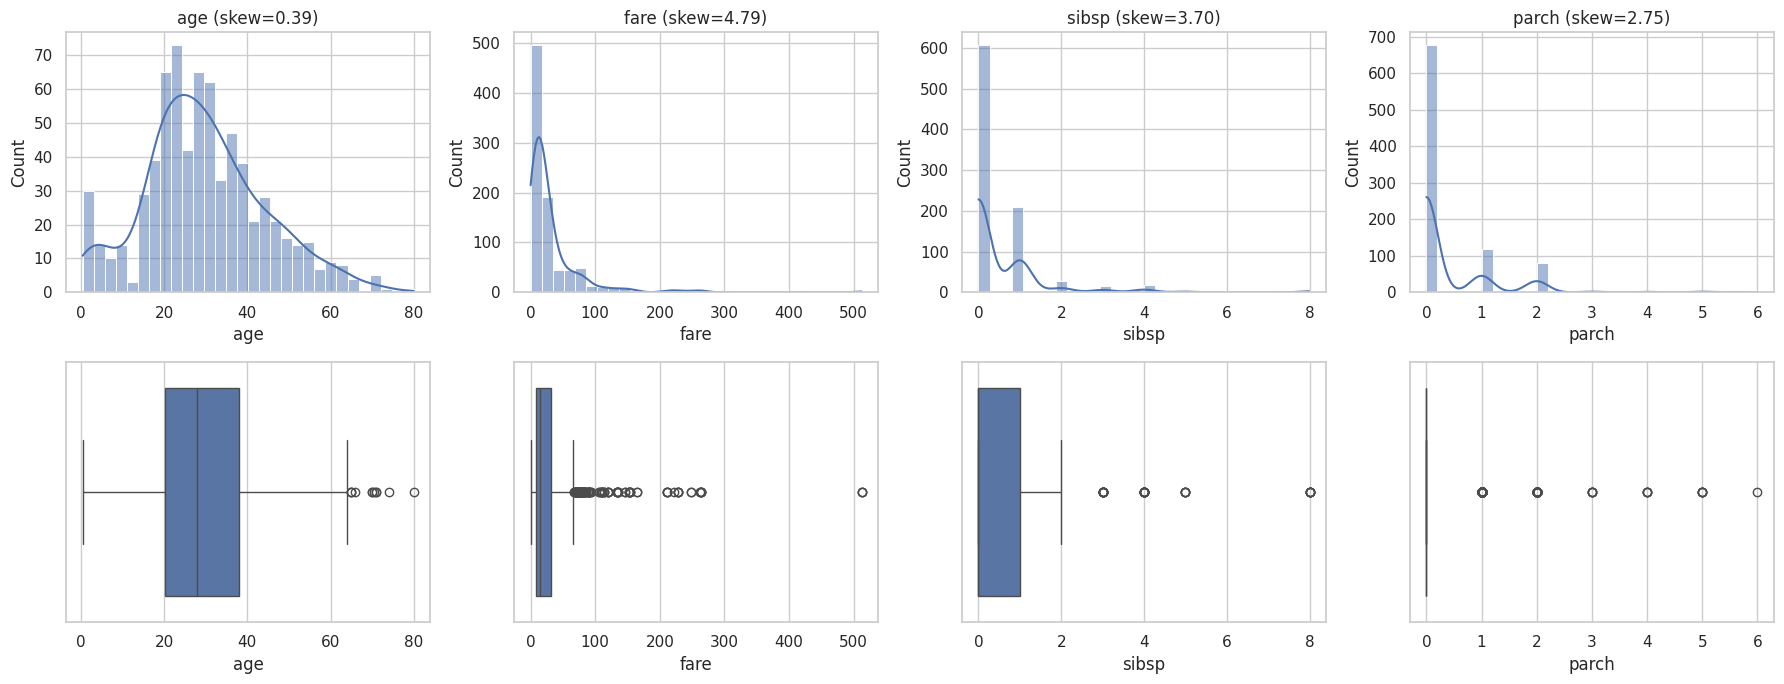

In [4]:
desc = df[num_cols].agg(["mean", "median", "std", "min", "max", "skew", "kurt"]).T.round(2); display(desc)
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c].dropna(), kde=True, bins=30, ax=axes[0, i]); axes[0, i].set_title(f"{c} (skew={df[c].skew():.2f})")
    sns.boxplot(x=df[c], ax=axes[1, i])
plt.tight_layout(); plt.show()

**Findings:** `age` is roughly symmetric with a slight right skew (≈ 0.39) around 28–30 years, with a spike of infants. `fare` is **extremely right-skewed** (≈ 4.8; median ≈ \$14, max ≈ \$512). `sibsp` and `parch` are zero-inflated counts. Typical of money variables, the fare distribution is not normal and would benefit from a log transform.

### Topic Explanation

This topic distinguishes input features used for analysis from the target variable the analysis may aim to explain or predict.

## 8. Analyse categorical features


pclass
        count   pct
pclass             
3         491  55.1
1         216  24.2
2         184  20.7

sex
        count   pct
sex                
male      577  64.8
female    314  35.2

embarked
          count   pct
embarked             
S           644  72.3
C           168  18.9
Q            77   8.6
NaN           2   0.2

who
       count   pct
who               
man      537  60.3
woman    271  30.4
child     83   9.3

alone
       count   pct
alone             
True     537  60.3
False    354  39.7


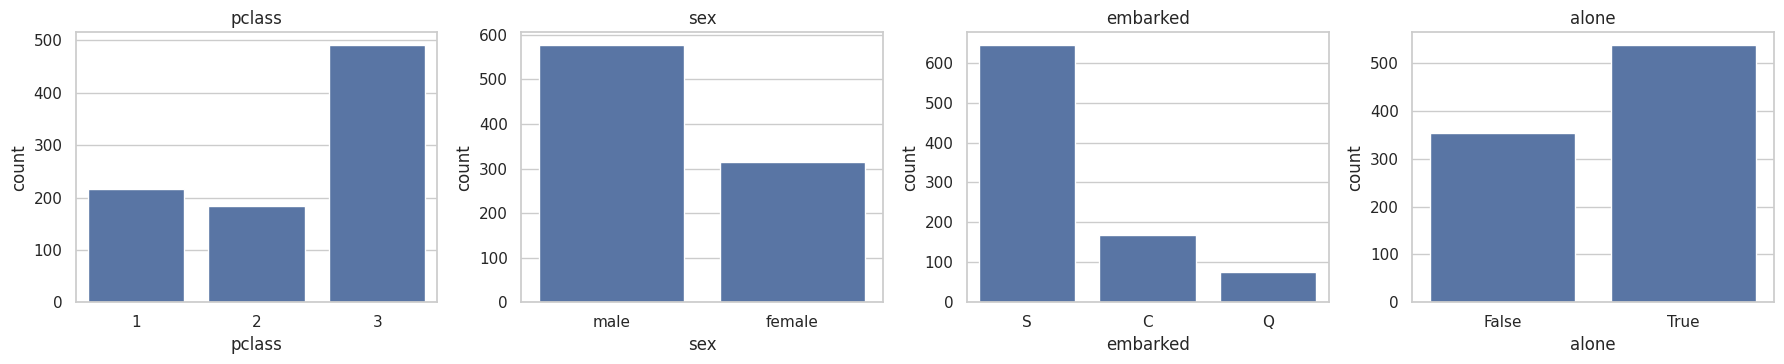

In [5]:
for c in ["pclass", "sex", "embarked", "who", "alone"]:
    vc = df[c].value_counts(dropna=False); print(f"\n{c}"); print(pd.DataFrame({"count": vc, "pct": (vc / len(df) * 100).round(1)}))
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, ["pclass", "sex", "embarked", "alone"]):
    sns.countplot(data=df, x=c, ax=ax); ax.set_title(c)
plt.tight_layout(); plt.show()

**Findings:** 3rd class is the largest group (55%), 65% of passengers are male, 72% embarked at Southampton and ≈ 60% travelled alone. Target balance: 38.4% survived / 61.6% died – a mild imbalance.

### Topic Explanation

This topic identifies unusually distant observations, compares detection methods, and considers whether they are errors or meaningful cases.

## 9. Detect outliers

In [6]:
def iqr_out(s):
    s = s.dropna(); q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    m = (s < q1 - 1.5 * i) | (s > q3 + 1.5 * i); return int(m.sum()), s[m]
for c in num_cols:
    n_out, vals = iqr_out(df[c]); z = np.abs(stats.zscore(df[c].dropna()))
    print(f"{c:<6} IQR outliers: {n_out:>3} ({n_out/df[c].notna().sum():.1%}) | |z|>3: {(z>3).sum()}")
print("\nTop fares:"); display(df.sort_values("fare", ascending=False)[["pclass", "sex", "age", "fare", "survived"]].head(8))
print("Fare == 0:", (df.fare == 0).sum())

age    IQR outliers:  11 (1.5%) | |z|>3: 2
fare   IQR outliers: 116 (13.0%) | |z|>3: 20
sibsp  IQR outliers:  46 (5.2%) | |z|>3: 30
parch  IQR outliers: 213 (23.9%) | |z|>3: 15

Top fares:


,pclass,sex,age,fare,survived
737,1,male,35.0,512.3292,1
679,1,male,36.0,512.3292,1
258,1,female,35.0,512.3292,1
438,1,male,64.0,263.0000,0
88,1,female,23.0,263.0000,1
27,1,male,19.0,263.0000,0
341,1,female,24.0,263.0000,1
311,1,female,18.0,262.3750,1


Fare == 0: 15


**Findings:** `fare` has many IQR outliers (≈ 13%) – up to ≈ \$512 – and `sibsp`/`parch` have flagged values (large families; for `parch` the IQR is 0, so *any* non-zero value is flagged – a limitation of the IQR rule on zero-inflated counts). The expensive fares belong to first-class passengers on shared tickets (genuine and valid); the highest values (≈ \$512) are plausibly the most expensive suites or group tickets. The 15 zero-fare rows are unusual (crew/staff or missing). **Decision: keep, transform (log fare)**, do not delete.

### Topic Explanation

This topic focuses on analyse correlations and relationships. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 11. Analyse correlations and relationships

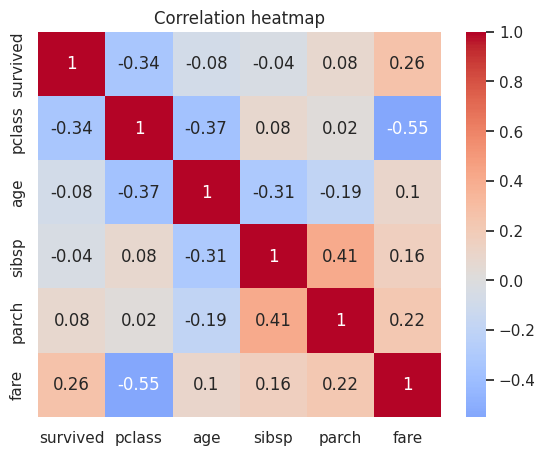

{'female': 0.742, 'male': 0.189}
{1: 0.63, 2: 0.473, 3: 0.242}
{False: 0.506, True: 0.304}


pclass,1,2,3
sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


In [7]:
corr = df[["survived", "pclass", "age", "sibsp", "parch", "fare"]].corr().round(2)
plt.figure(figsize=(6.5, 5)); sns.heatmap(corr, annot=True, cmap="coolwarm", center=0); plt.title("Correlation heatmap"); plt.show()
print(df.groupby("sex").survived.mean().round(3).to_dict())
print(df.groupby("pclass").survived.mean().round(3).to_dict())
print(df.groupby("alone").survived.mean().round(3).to_dict())
display(df.pivot_table(index="sex", columns="pclass", values="survived", aggfunc="mean").round(2))

**Findings:** `pclass` correlates –0.34 with survival (higher class = lower number = better survival); `fare` +0.26; `age` only –0.08 linearly. `fare` and `pclass` are linked (–0.55). Survival: women ≈ 74% vs men ≈ 19%; 1st class ≈ 63%, 2nd ≈ 47%, 3rd ≈ 24%. The pivot shows the interaction: women in 1st/2nd class survived ≈ 92–97%, while men in 2nd/3rd class survived only ≈ 14–16%.

### Topic Explanation

This topic focuses on meaningful visualizations. Read the existing notes, follow the example cells, and explain what the resulting output tells you.

## 12. Meaningful visualizations

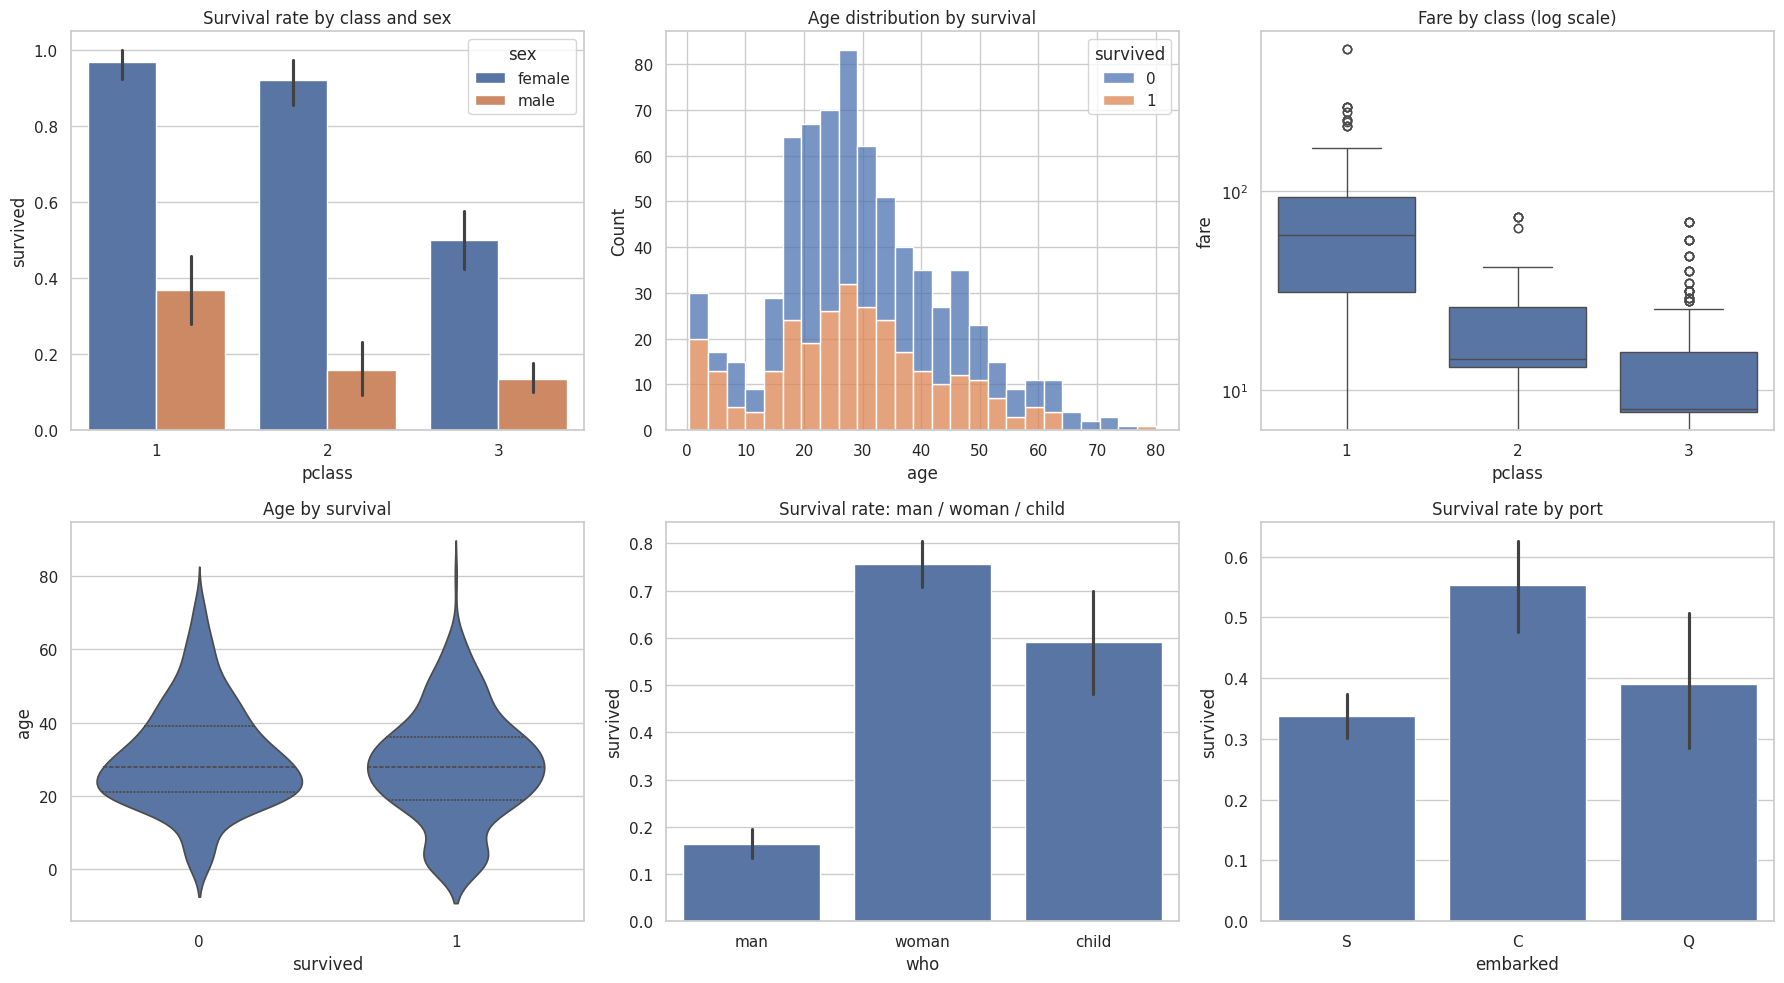

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.barplot(data=df, x="pclass", y="survived", hue="sex", ax=axes[0, 0]); axes[0, 0].set_title("Survival rate by class and sex")
sns.histplot(data=df, x="age", hue="survived", multiple="stack", bins=25, ax=axes[0, 1]); axes[0, 1].set_title("Age distribution by survival")
sns.boxplot(data=df, x="pclass", y="fare", ax=axes[0, 2]); axes[0, 2].set_yscale("log"); axes[0, 2].set_title("Fare by class (log scale)")
sns.violinplot(data=df, x="survived", y="age", ax=axes[1, 0], inner="quartile"); axes[1, 0].set_title("Age by survival")
sns.barplot(data=df, x="who", y="survived", ax=axes[1, 1]); axes[1, 1].set_title("Survival rate: man / woman / child")
sns.barplot(data=df, x="embarked", y="survived", ax=axes[1, 2]); axes[1, 2].set_title("Survival rate by port")
plt.tight_layout(); plt.show()

## 13. Important patterns  and  14. Insights

* **Sex and class dominate survival.** Women had ≈ 4× the survival rate of men; first-class passengers survived at 2.6× the rate of third-class passengers. These are the "women and children first" rule and unequal access to lifeboats by class.
* **Children (`who = child`) survive better than men** – age matters mostly at the extremes (infants).
* **Port of embarkation (C vs S)** looks predictive but is mostly a *proxy for class* (Cherbourg boarded more first-class passengers) → confounding.
* **Travelling alone** is associated with lower survival than travelling with family, but this is confounded with sex (most lone travellers are men).
* **Fare** is a proxy for class; keep one of them, log-transform fare.
* Missing `age` is not random (more frequent in 3rd class), so imputing with the global median would hide a pattern; group-wise imputation by title/class is better.
* **Association ≠ causation:** these results describe who survived, not why.

### Topic Explanation

This topic translates observed data patterns into business meaning and practical actions, while keeping conclusions tied to the evidence.

## 15. Recommendations for the next preprocessing stage

| Area | Recommendation |
|---|---|
| Leakage | Drop `alive` (duplicate of target); drop duplicated-information columns (`class`, `embark_town`, possibly `who`, `adult_male`) |
| Missing | `age`: impute using group medians (class × sex); `deck`: drop or create 'Unknown' category / `has_deck` flag; `embarked`: fill with mode |
| Duplicates | Review the 107 duplicate rows; likely keep |
| Encoding | One-hot `sex`, `embarked`; keep `pclass` ordinal |
| Transformation | log1p(`fare`); consider age bins |
| Feature engineering | `family_size = sibsp + parch + 1`, `is_alone`, `title` (from name if available), `has_deck` |
| Outliers | Keep fares; cap/transform if the model is sensitive |
| Target | Stratified split; mild imbalance (38/62) → report F1/ROC-AUC |